# 12 · Côte d'Ivoire : cacao, café et sites touristiques

Infographies tirées des fichiers de [`datasets/`](datasets/) :

| Fichier | Contenu | Source |
|---|---|---|
| `cacao_prix_production_1960_2024.csv` | prix au producteur et production commercialisée de cacao | `exportIndicateurs.csv` |
| `cacao_cafe_regions.csv` | production de café et de cacao par région, 2022-2023 | fichier Excel « Répartition de la production… » |
| `cacao_cafe_chiffres.csv` | superficie, production, prix, revenus, exportations | « Statistiques globales sur le secteur cacao et café » |
| `financement_agricole.csv` | financement des projets agricoles (millions de F CFA) | fichier Excel « Financement… » |
| `pyramide_population_agricole_2024.csv` | population agricole par âge (centaines de milliers) | fichier Excel « Pyramide des âges… » |
| `civ_regions.geojson` | limites des 33 régions et districts | [geoBoundaries](https://www.geoboundaries.org) (CC BY 4.0) |
| `sites-touristiques-en-cote-divoire.geojson` | 43 sites touristiques (points) | OpenStreetMap |

Les CSV sont les fichiers Excel d'origine remis en colonnes simples (sans les lignes « Total général »).

In [1]:
import geopandas as gpd
import pandas as pd
from plutovizu import Chart

cacao = ['#5b3a29', '#b5733b', '#e3b15a', '#8a9a5b']   # cabosse, fève, or, feuille

## Soixante ans de cacao

`area` pour la production, `step` pour le prix (fixé par campagne : une marche par an). `annotation` raconte les deux ou trois faits marquants.

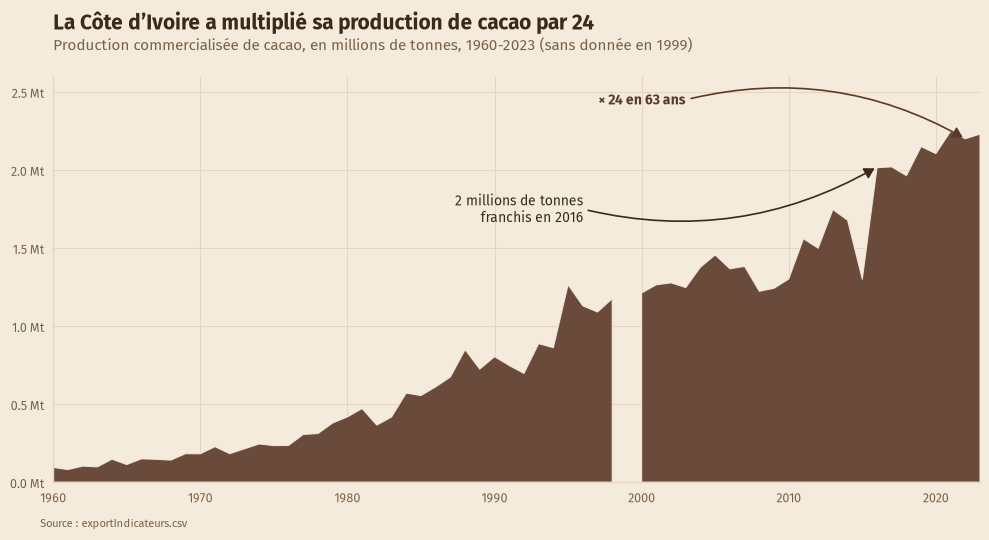

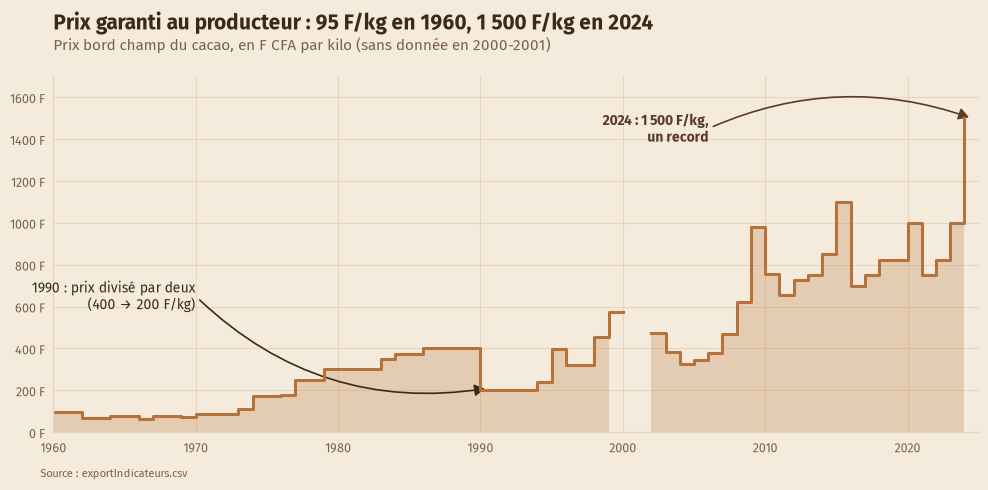

In [2]:
serie = pd.read_csv('datasets/cacao_prix_production_1960_2024.csv')
serie['production_mt'] = serie['production_t'] / 1e6

(Chart(serie, figsize=(10, 5.5), theme='sahel')
    .set_colors(cacao)
    .area('annee', 'production_mt', alpha=0.9)
    .set_limits(xlim=(1960, 2023), ylim=(0, 2.6))
    .tick_format(y='{:.1f} Mt')
    .annotation('× 24 en 63 ans', xy=(2022, 2.2), xytext=(2003, 2.45), radius=-0.2,
                fontweight='bold', color=cacao[0])
    .annotation('2 millions de tonnes\nfranchis en 2016', xy=(2016, 2.02), xytext=(1996, 1.75),
                radius=0.2)
    .title('La Côte d’Ivoire a multiplié sa production de cacao par 24', loc='left',
           fontweight='bold')
    .subtitle('Production commercialisée de cacao, en millions de tonnes, 1960-2023 (sans donnée en 1999)')
    .labels('', '')
    .caption('Source : exportIndicateurs.csv', loc='left')
    .tight_layout()
    .show())

(Chart(serie, figsize=(10, 5), theme='sahel')
    .set_colors([cacao[1]])
    .step('annee', 'prix_fcfa_kg', where='post', fill=True, alpha=0.25)
    .set_limits(xlim=(1960, 2025), ylim=(0, 1700))
    .tick_format(y='{:.0f} F')
    .annotation('1990 : prix divisé par deux\n(400 → 200 F/kg)', xy=(1990.5, 210),
                xytext=(1970, 650), radius=0.25)
    .annotation('2024 : 1 500 F/kg,\nun record', xy=(2024.5, 1500), xytext=(2006, 1450),
                radius=-0.2, fontweight='bold', color=cacao[0])
    .title('Prix garanti au producteur : 95 F/kg en 1960, 1 500 F/kg en 2024', loc='left',
           fontweight='bold')
    .subtitle('Prix bord champ du cacao, en F CFA par kilo (sans donnée en 2000-2001)')
    .labels('', '')
    .caption('Source : exportIndicateurs.csv', loc='left')
    .tight_layout()
    .show())

## Où pousse le cacao ?

`choropleth` sur les régions (geoBoundaries) jointes aux tonnages : `scheme='natural'` classe les régions par seuils naturels, et les régions sans données (le nord, hors zone cacaoyère) restent grisées. Seules les régions de plus de 100 000 tonnes sont nommées. `dumbbell` montre ensuite le recul de 2023 région par région.

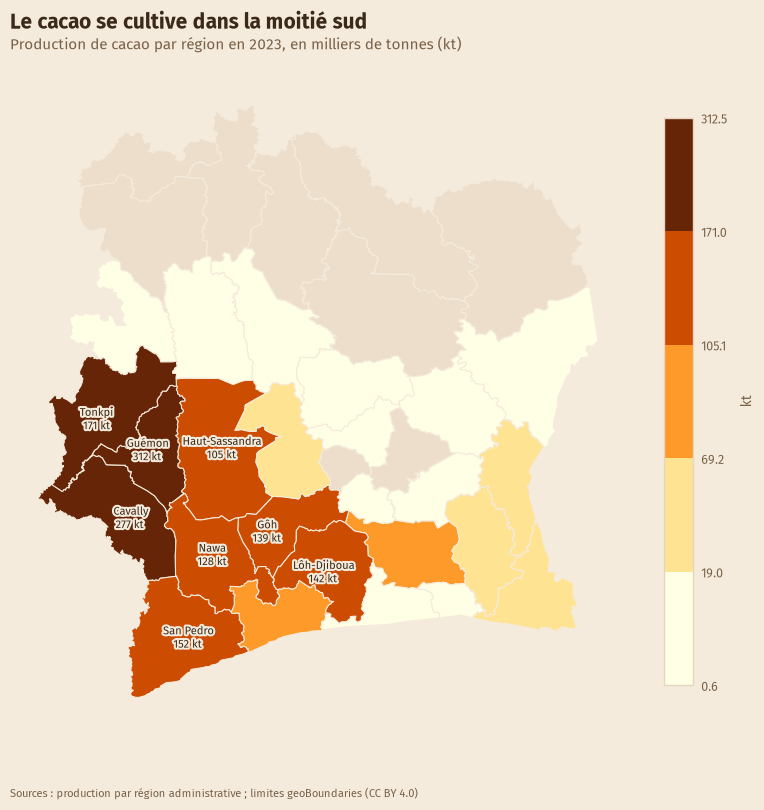

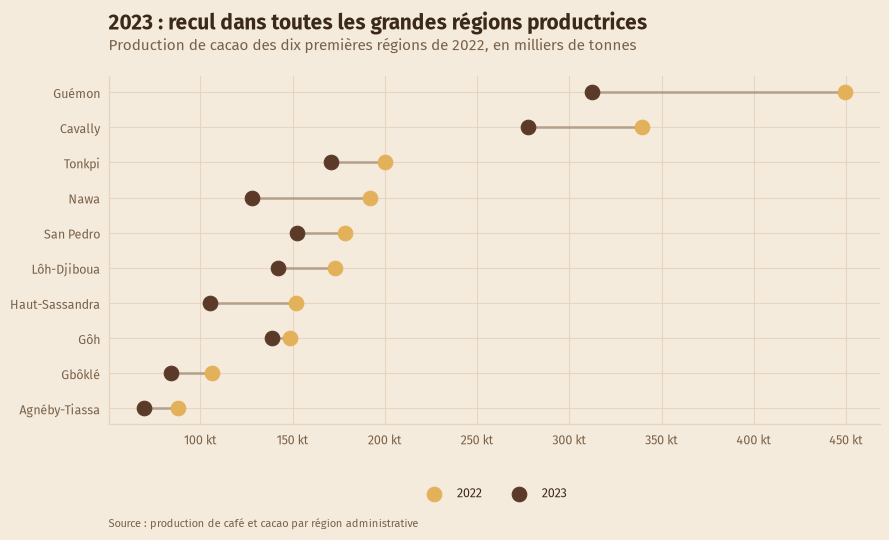

In [3]:
regions = gpd.read_file('datasets/civ_regions.geojson')
production = pd.read_csv('datasets/cacao_cafe_regions.csv')
cacao_2023 = production.query("produit == 'Cacao' and annee == 2023")

carte = regions.merge(cacao_2023, on='region', how='left')
carte['kt'] = carte['tonnes'] / 1000
carte['etiquette'] = (carte['region'] + '\n' + carte['kt'].round().astype('Int64').astype(str)
                      + ' kt').where(carte['kt'] > 100, '')

(Chart(carte, figsize=(8, 8.5), theme='sahel')
    .choropleth('kt', labels='etiquette', cmap='YlOrBr', scheme='natural', k=5)
    .title('Le cacao se cultive dans la moitié sud', loc='left', fontweight='bold')
    .subtitle('Production de cacao par région en 2023, en milliers de tonnes (kt)')
    .caption('Sources : production par région administrative ; limites geoBoundaries (CC BY 4.0)',
             loc='left')
    .tight_layout()
    .show())

recul = (production.query("produit == 'Cacao'")
         .pivot(index='region', columns='annee', values='tonnes').div(1000)
         .nlargest(10, 2022).iloc[::-1].reset_index())
recul.columns = ['region', '2022', '2023']

(Chart(recul, figsize=(9, 5.5), theme='sahel')
    .dumbbell('region', '2022', '2023', color_start=cacao[2], color_end=cacao[0], markersize=110)
    .tick_format(x='{:.0f} kt')
    .set_legend(location='below')
    .title('2023 : recul dans toutes les grandes régions productrices', loc='left',
           fontweight='bold')
    .subtitle('Production de cacao des dix premières régions de 2022, en milliers de tonnes')
    .labels('', '')
    .caption('Source : production de café et cacao par région administrative', loc='left')
    .tight_layout()
    .show())

## Le secteur en chiffres

Évolution 2022 → 2023 calculée avec `pivot` puis tracée en barres horizontales groupées ; financement des projets en anneau (`donut`) ; population agricole en pyramide des âges (`pyramid`).

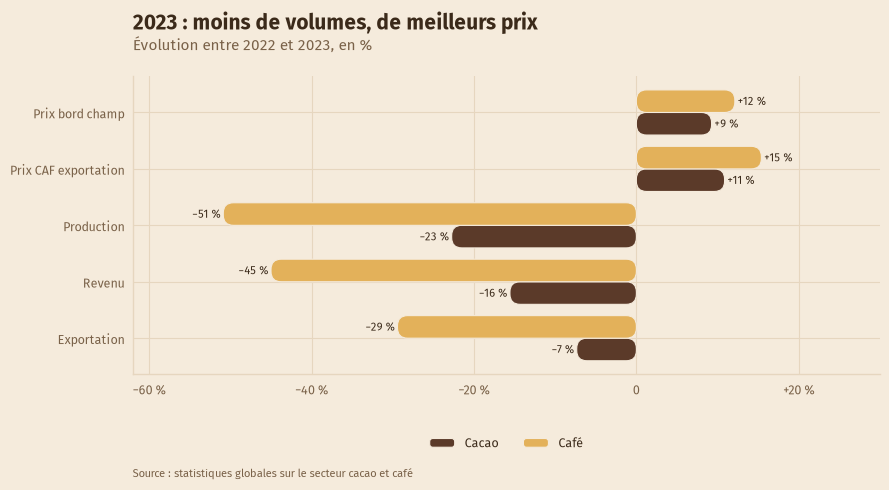

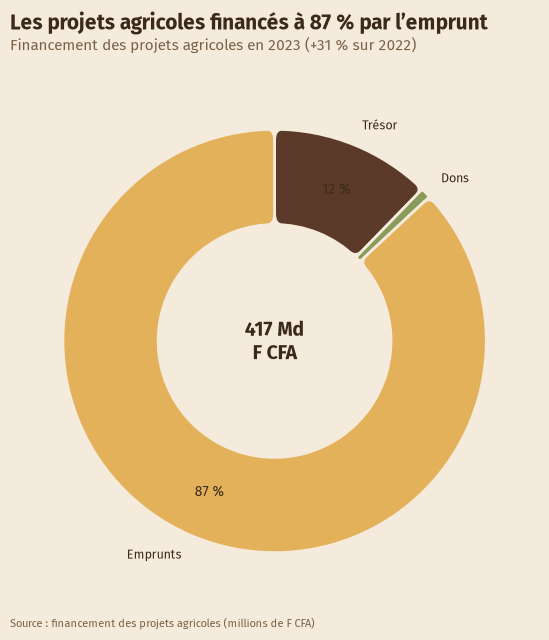

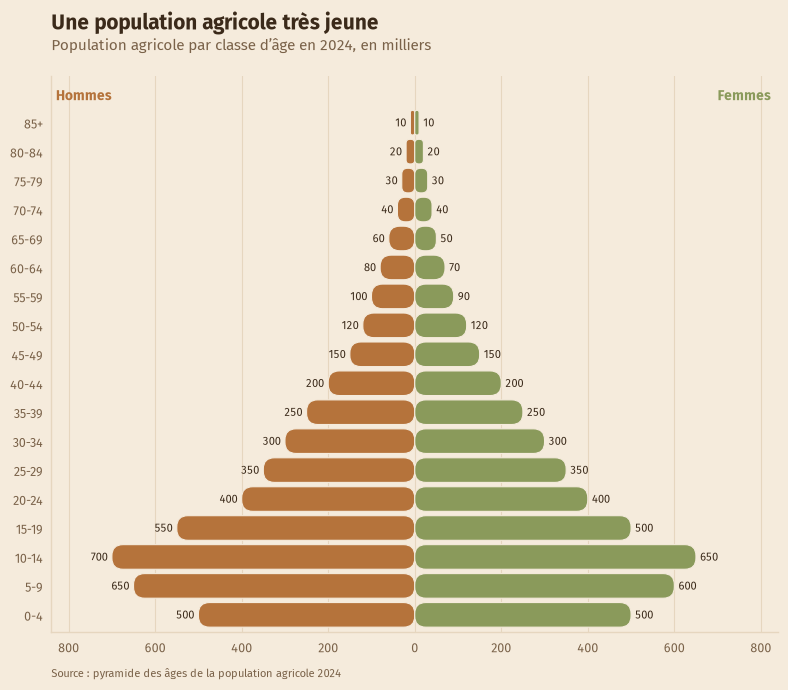

In [4]:
chiffres = pd.read_csv('datasets/cacao_cafe_chiffres.csv')
evolution = (chiffres.pivot_table(index='rubrique', columns=['produit', 'annee'], values='valeur')
             .pipe(lambda t: (t.xs(2023, axis=1, level=1) / t.xs(2022, axis=1, level=1) - 1) * 100)
             .loc[['Exportation (Tonnes)', 'Revenu (milliards de FCFA)', 'Production (Tonnes)',
                   'Prix CAF exportation (F/Kg)', 'Prix bord champ (F/Kg)']]
             .rename(index=lambda r: r.split(' (')[0])
             .reset_index())
signe = lambda v: f'{v:+.0f} %'.replace('-', '−') if round(v) else '0'

(Chart(evolution, figsize=(9, 5), theme='sahel')
    .set_colors([cacao[0], cacao[2]])
    .bar('rubrique', ['Cacao', 'Café'], horizontal=True, alpha=1, show_values=True,
         value_format=signe)
    .tick_format(x=signe)
    .set_limits(xlim=(-62, 30))
    .set_legend(location='below')
    .title('2023 : moins de volumes, de meilleurs prix', loc='left', fontweight='bold')
    .subtitle('Évolution entre 2022 et 2023, en %')
    .labels('', '')
    .caption('Source : statistiques globales sur le secteur cacao et café', loc='left')
    .tight_layout()
    .show())

financement = pd.read_csv('datasets/financement_agricole.csv').query('annee == 2023')
total = financement['millions_fcfa'].sum() / 1000

(Chart(financement, figsize=(8.5, 6.5), theme='sahel')
    .set_colors([cacao[0], cacao[3], cacao[2]])
    .donut('millions_fcfa', labels='source', center_text=f'{total:.0f} Md\nF CFA')
    .title('Les projets agricoles financés à 87 % par l’emprunt', loc='left', fontweight='bold')
    .subtitle('Financement des projets agricoles en 2023 (+31 % sur 2022)')
    .caption('Source : financement des projets agricoles (millions de F CFA)', loc='left')
    .tight_layout()
    .show())

population = pd.read_csv('datasets/pyramide_population_agricole_2024.csv')
population[['Hommes', 'Femmes']] = population[['hommes', 'femmes']] * 100   # en milliers

(Chart(population, figsize=(8, 7), theme='sahel')
    .pyramid('age', 'Hommes', 'Femmes', colors=[cacao[1], cacao[3]], show_values=True)
    .title('Une population agricole très jeune', loc='left', fontweight='bold')
    .subtitle('Population agricole par classe d’âge en 2024, en milliers')
    .labels('', '')
    .caption('Source : pyramide des âges de la population agricole 2024', loc='left')
    .tight_layout()
    .show())

## Carte des sites touristiques

Le GeoJSON se lit avec `geopandas` et se passe tel quel à `map_points` : plus besoin de colonnes `lon` / `lat`. `boundary=regions` dessine les régions sous les points, sans fond de carte web (`basemap=False`). Les noms des parcs nationaux sont placés sans chevauchement (ceux qui ne tiennent pas sont listés dans `hidden_labels`).

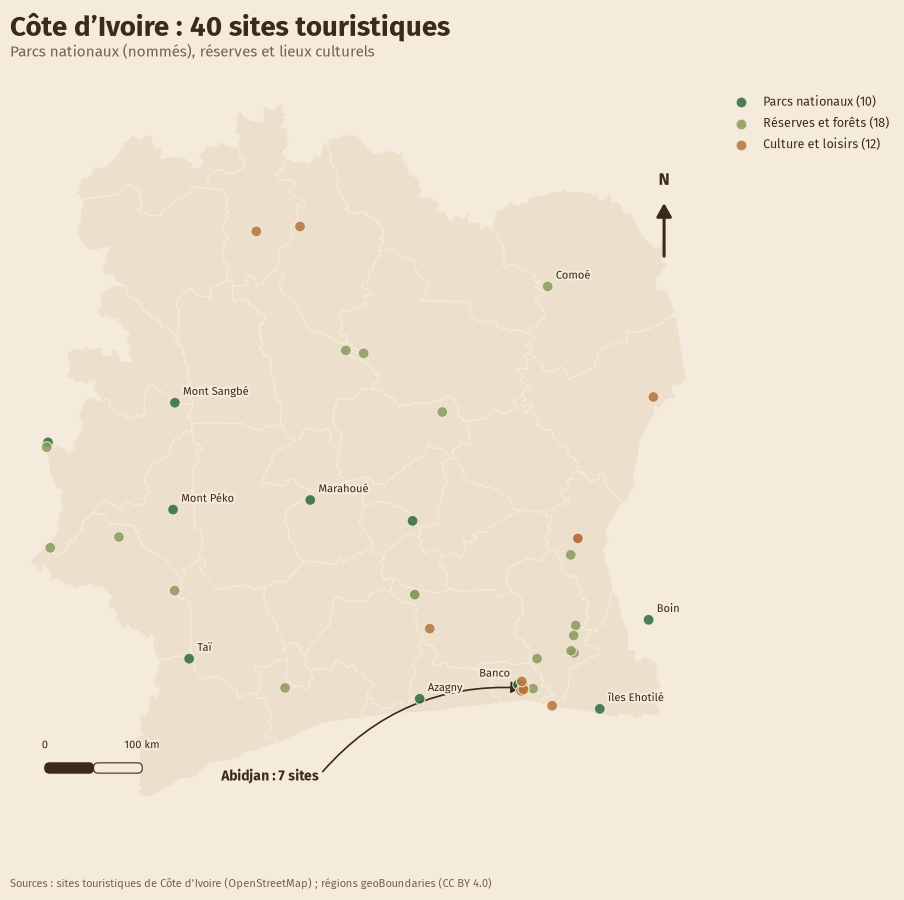

In [5]:
sites = (gpd.read_file('datasets/sites-touristiques-en-cote-divoire.geojson')
         .rename(columns={"Nom_de_l'établissement": 'site'}))
sites['site'] = sites['site'].str.replace('’', "'")
sites = sites[~sites['site'].str.lower().duplicated()]   # même site saisi deux fois
familles = {'Parc national': 'Parcs nationaux', 'Zone protégée': 'Réserves et forêts'}
sites['type'] = sites['Catégorie'].map(familles).fillna('Culture et loisirs')
sites['type'] += ' (' + sites['type'].map(sites['type'].value_counts()).astype(str) + ')'
parc = sites['site'].str.contains('parc national|national park', case=False)
sites['parc'] = sites['site'].where(parc, '').str.replace(
    r"(?i)^parc national (de la |des |du |de |d')?| National Park$", '', regex=True)
abidjan = sites.cx[-4.15:-3.9, 5.25:5.45]

(Chart(sites, figsize=(9, 9.5), theme='sahel')
    .map_points(group='type', labels='parc', boundary=regions, basemap=False,
                colors=dict(zip(sorted(sites['type'].unique()), [cacao[1], '#2f6b3b', cacao[3]])))
    .annotation(f'Abidjan : {len(abidjan)} sites', xy=(-4.0, 5.36), xytext=(-5.9, 4.55),
                radius=-0.25, fontweight='bold')
    .north_arrow()
    .scale_bar()
    .set_legend(location='upper left')
    .title(f'Côte d’Ivoire : {len(sites)} sites touristiques', loc='left', fontsize=20,
           fontweight='bold')
    .subtitle('Parcs nationaux (nommés), réserves et lieux culturels')
    .caption('Sources : sites touristiques de Côte d’Ivoire (OpenStreetMap) ; '
             'régions geoBoundaries (CC BY 4.0)', loc='left')
    .tight_layout()
    .show())